# Uber Pickups : Hot-zones à New York

# Bloc 3 CDSD RNCP 35288 JEDHA
# Schuyler Gilmer Goncalves

## Objectif

- Identifier les zones où la demande Uber est la plus forte.
- Aider les chauffeurs à se positionner au bon endroit au bon moment.
- Comparer deux méthodes de clustering :
  - **K-Means**
  - **DBSCAN**

In [1]:
import os
import glob
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

from IPython.display import display
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# Chargement donnée & preparation

- 6 fichiers Uber NYC d'avril à septembre 2014
- Je garde uniquement :
  - latitude 
  - longitude 
  - mois 
  - jour de semaine 
  - heure

In [2]:

from pathlib import Path
import zipfile

current_dir = Path.cwd()

project_root = (
    current_dir.parent
    if current_dir.name in {"notebook", "notebooks"}
    else current_dir
)

archive = project_root / "data" / "raw" / "uber-trip-data.zip"

if not archive.is_file():
    raise FileNotFoundError(f"Archive introuvable : {archive}")

with zipfile.ZipFile(archive) as z:
    fichiers = sorted(
        nom for nom in z.namelist()
        if Path(nom).name.startswith("uber-raw-data-")
        and Path(nom).name.endswith("14.csv")
        and not nom.startswith("__MACOSX/")
    )

print("Fichiers trouvés :", len(fichiers))

if len(fichiers) != 6:
    raise ValueError(f"6 CSV attendus, trouvés : {fichiers}")


Fichiers trouvés : 6


In [3]:

parties = []

with zipfile.ZipFile(archive) as z:
    for fichier in fichiers:
        with z.open(fichier) as contenu:
            temp = pd.read_csv(
                contenu,
                usecols=["Date/Time", "Lat", "Lon"]
            )

        date = pd.to_datetime(
            temp["Date/Time"],
            format="%m/%d/%Y %H:%M:%S"
        )

        parties.append(
            pd.DataFrame({
                "Latitude": temp["Lat"].astype("float32"),
                "Longitude": temp["Lon"].astype("float32"),
                "Mois": date.dt.month.astype("int8"),
                "Jour": date.dt.dayofweek.astype("int8"),
                "Heure": date.dt.hour.astype("int8")
            })
        )

data = pd.concat(parties, ignore_index=True)
del parties

print("Dimensions :", data.shape)
display(data.head())


Dimensions : (4534327, 5)


,Latitude,Longitude,Mois,Jour,Heure
0,40.769001,-73.954903,4,1,0
1,40.726700,-74.034500,4,1,0
2,40.731602,-73.987297,4,1,0
3,40.758801,-73.977600,4,1,0
4,40.759399,-73.972198,4,1,0


## Nettoyage

- Je vérifie les valeurs manquantes.
- Je retire seulement les coordonnées très éloignées de New York pour éviter de perturber les clusters.

In [4]:
print("Valeurs manquantes :")
display(data.isna().sum())

avant = len(data)

data = data[
    data["Latitude"].between(40.50, 41.00)
    & data["Longitude"].between(-74.25, -73.70)
].copy()

print("Pickups conservés :", len(data))
print("Part retirée :", f"{(avant - len(data)) / avant:.2%}")

Valeurs manquantes :


Latitude     0
Longitude    0
Mois         0
Jour         0
Heure        0
dtype: int64

Pickups conservés : 4507763
Part retirée : 0.59%



- Le dataset contient environ 4,5 millions de pickups.
- Moins de 1 % des lignes sont retirées.
- La quantité de données est suffisante pour analyser les hot-zones.

# Exploratory Data Analysis 

- Je regarde d'abord quand la demande est la plus forte.

In [5]:
jours = [
    "Lundi", "Mardi", "Mercredi",
    "Jeudi", "Vendredi", "Samedi", "Dimanche"
]

mois = {
    4: "Avril", 5: "Mai", 6: "Juin",
    7: "Juillet", 8: "Août", 9: "Septembre"
}

par_mois = data.groupby("Mois").size()
par_jour = data.groupby("Jour").size()
par_heure = data.groupby("Heure").size()

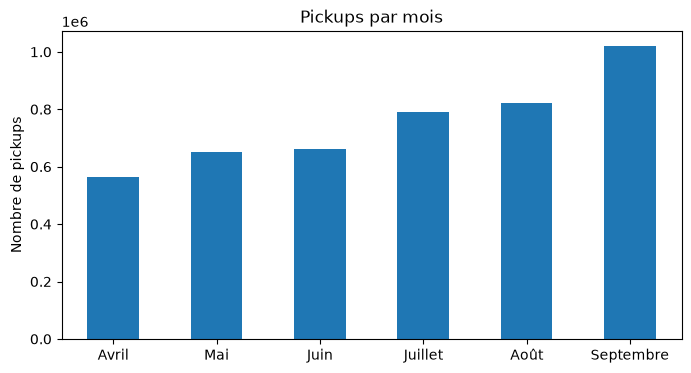

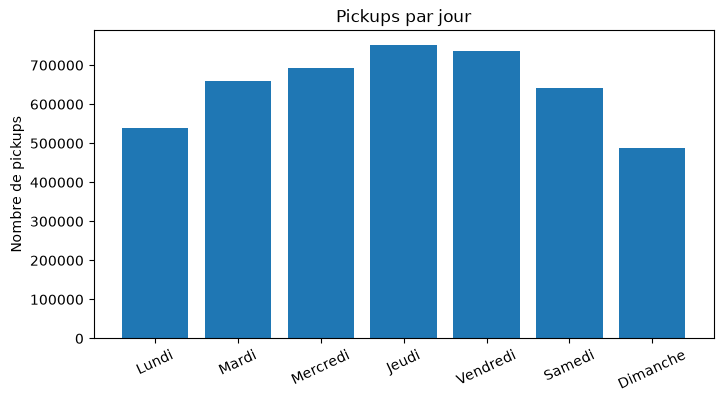

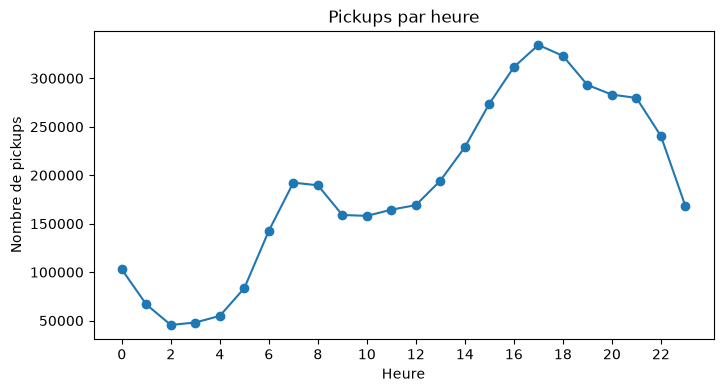

In [6]:
plt.figure(figsize=(8, 4))
par_mois.rename(index=mois).plot(kind="bar")
plt.title("Pickups par mois")
plt.xlabel("")
plt.ylabel("Nombre de pickups")
plt.xticks(rotation=0)
plt.show()

plt.figure(figsize=(8, 4))
plt.bar(jours, par_jour.values)
plt.title("Pickups par jour")
plt.ylabel("Nombre de pickups")
plt.xticks(rotation=25)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(par_heure.index, par_heure.values, marker="o")
plt.title("Pickups par heure")
plt.xlabel("Heure")
plt.ylabel("Nombre de pickups")
plt.xticks(range(0, 24, 2))
plt.show()

- Le volume de pickups augmente globalement au cours de la période.
- Le jeudi et le vendredi sont les jours les plus actifs.
- Le principal pic apparaît en fin d'après-midi / début de soirée.

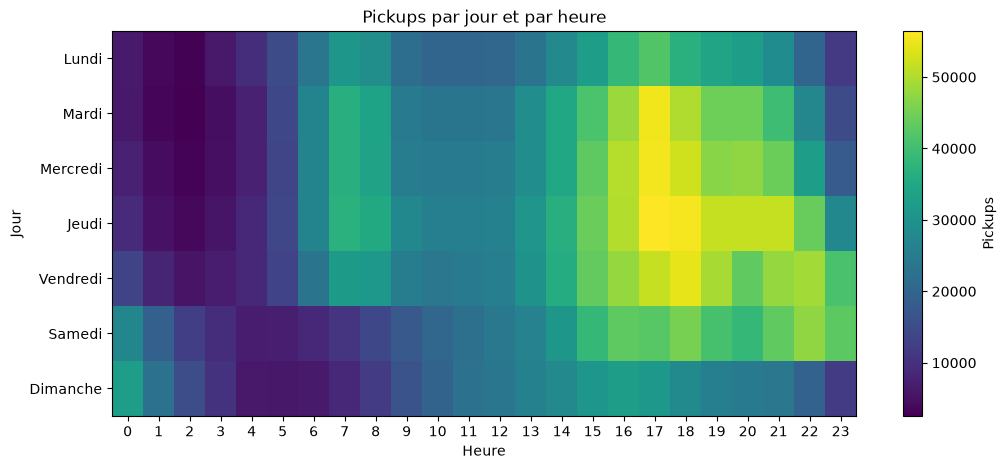

In [7]:
# heure x jour

jour_heure = (
    data.groupby(["Jour", "Heure"])
    .size()
    .unstack(fill_value=0)
)

plt.figure(figsize=(12, 5))
plt.imshow(jour_heure, aspect="auto")
plt.colorbar(label="Pickups")
plt.yticks(range(7), jours)
plt.xticks(range(24), range(24))
plt.title("Pickups par jour et par heure")
plt.xlabel("Heure")
plt.ylabel("Jour")
plt.show()

- La demande varie selon le jour et l'heure.
- Il est donc plus pertinent de proposer des hot-zones dynamiques qu'une seule carte pour toute la semaine.

## Heures de pointe par jour

- Je regarde aussi l'heure où le nombre de pickups est maximal pour chaque jour.


In [8]:
heures_pointe = jour_heure.idxmax(axis=1)

table_pointe = pd.DataFrame({
    "Jour": jours,
    "Heure_pointe": heures_pointe.values,
    "Pickups": jour_heure.max(axis=1).values
})

display(table_pointe)


,Jour,Heure_pointe,Pickups
0,Lundi,17,41845
1,Mardi,17,55294
2,Mercredi,17,55425
3,Jeudi,17,56455
4,Vendredi,18,54485
5,Samedi,22,47479
6,Dimanche,16,32813


- Les jours de semaine culminent surtout en fin d'après-midi.
- Le samedi est plus tardif.
- Cela renforce l'idée de recommander les hot-zones selon le jour et l'heure


## Carte des pickups

- J'affiche seulement un échantillon pour garder une carte lisible.

In [9]:
carte_sample = data.sample(5000, random_state=0).copy()
carte_sample["Jour"] = carte_sample["Jour"].map(dict(enumerate(jours)))

fig = px.scatter_map(
    carte_sample,
    lat="Latitude",
    lon="Longitude",
    hover_data=["Jour", "Heure"],
    zoom=9,
    height=550,
    title="Échantillon des pickups Uber à New York"
)

fig.update_layout(
    map_style="open-street-map",
    margin=dict(l=0, r=0, t=50, b=0)
)

fig.show()

###  géographie

- Les pickups sont très concentrés dans Manhattan.
- D'autres zones importantes apparaissent autour des grands pôles de transport (aeroport)

# K-Means clustering

- Je commence par un créneau : vendredi à 18h.
- C'est une période de forte demande.

In [10]:
focus = data[
    (data["Jour"] == 4)
    & (data["Heure"] == 18)
].copy()

print("Pickups vendredi à 18h :", len(focus))

Pickups vendredi à 18h : 54485


## Choix du nombre de clusters

- Je teste plusieurs valeurs de K
- Je regarde :
  - l'inertie 
  - le silhouette score

In [11]:
sample_k = focus[
    ["Latitude", "Longitude"]
].sample(20000, random_state=0)

resultats_k = []

for k in range(3, 11):
    modele = KMeans(
        n_clusters=k,
        random_state=0,
        n_init=10
    )

    labels = modele.fit_predict(sample_k)

    resultats_k.append({
        "K": k,
        "Inertie": modele.inertia_,
        "Silhouette": silhouette_score(
            sample_k,
            labels,
            sample_size=3000,
            random_state=0
        )
    })

resultats_k = pd.DataFrame(resultats_k)
display(resultats_k.round(3))

,K,Inertie,Silhouette
0,3,24.641,0.410
1,4,19.924,0.425
2,5,15.548,0.437
3,6,11.435,0.454
4,7,9.546,0.422
5,8,8.390,0.393
6,9,7.245,0.433
7,10,6.314,0.394


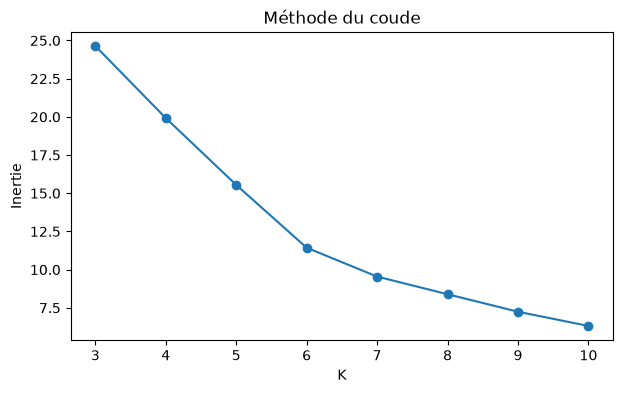

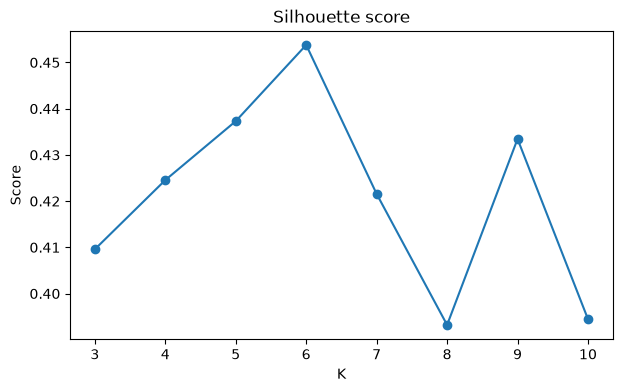

In [12]:
plt.figure(figsize=(7, 4))
plt.plot(resultats_k["K"], resultats_k["Inertie"], marker="o")
plt.title("Méthode du coude")
plt.xlabel("K")
plt.ylabel("Inertie")
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(resultats_k["K"], resultats_k["Silhouette"], marker="o")
plt.title("Silhouette score")
plt.xlabel("K")
plt.ylabel("Score")
plt.show()

### Choix de K

- Le silhouette score varie peu, entre environ 0,39 et 0,45 et n'est pas monotone
- Il baisse jusqu'à K = 8, puis remonte ensuite.
- Comme il est calculé sur un échantillon de 3 000 points, je ne l'utilise pas seul pour choisir `K`.
- Le coude situe une zone raisonnable autour de 6 à 8 clusters.
- Je retiens 8 clusters pour avoir un découpage un peu plus fin tout en gardant une carte lisible et exploitable par un chauffeur.


In [13]:
def hot_zones(df, k=8, max_lignes=30000):
    train = df[["Latitude", "Longitude"]]

    if len(train) > max_lignes:
        train = train.sample(max_lignes, random_state=0)

    modele = KMeans(
        n_clusters=k,
        random_state=0,
        n_init=10
    ).fit(train)

    labels = modele.predict(
        df[["Latitude", "Longitude"]]
    )

    centres = pd.DataFrame(
        modele.cluster_centers_,
        columns=["Latitude", "Longitude"]
    )

    comptes = pd.Series(labels).value_counts()

    centres["Pickups"] = [
        comptes.get(i, 0) for i in range(k)
    ]
    centres["Part_%"] = centres["Pickups"] / len(df) * 100

    return (
        centres.sort_values("Pickups", ascending=False)
        .reset_index(drop=True),
        modele
    )

In [14]:
centres_kmeans, modele_kmeans = hot_zones(focus, 8)

display(centres_kmeans.round(3))

fig = px.scatter_map(
    centres_kmeans,
    lat="Latitude",
    lon="Longitude",
    size="Pickups",
    hover_data={"Part_%": ":.1f"},
    zoom=9.5,
    height=560,
    title="Hot-zones K-Means — vendredi 18h"
)

fig.update_layout(
    map_style="open-street-map",
    margin=dict(l=0, r=0, t=50, b=0)
)

fig.show()

,Latitude,Longitude,Pickups,Part_%
0,40.754002,-73.982002,25469,46.745
1,40.726002,-74.000999,16445,30.183
2,40.780998,-73.958000,4115,7.553
3,40.712002,-73.945999,2918,5.356
4,40.673000,-73.980003,2715,4.983
5,40.782001,-73.862000,1542,2.830
6,40.657001,-73.785004,910,1.670
7,40.703999,-74.176003,371,0.681



- K-Means transforme des milliers de pickups en 8 zones
- La taille des cercles montre les zones qui concentrent le plus de demande

## Hot-zones par jour de semaine

In [15]:
zones_jour = {}
resume_jours = []

for numero, nom in enumerate(jours):
    subset = data[data["Jour"] == numero]
    centres, _ = hot_zones(subset, 8)
    zones_jour[nom] = centres

    resume_jours.append({
        "Jour": nom,
        "Pickups": len(subset),
        "Part_zone_1_%": centres.iloc[0]["Part_%"],
        "Part_2_zones_%": centres.iloc[:2]["Part_%"].sum()
    })

resume_jours = pd.DataFrame(resume_jours)
display(resume_jours.round(1))

,Jour,Pickups,Part_zone_1_%,Part_2_zones_%
0,Lundi,538581,34.0,62.5
1,Mardi,660639,46.0,67.5
2,Mercredi,693052,37.8,68.3
3,Jeudi,751430,38.5,74.1
4,Vendredi,736606,31.8,60.2
5,Samedi,640754,46.6,73.1
6,Dimanche,486701,37.7,66.4


In [16]:
fig = go.Figure()

for i, nom in enumerate(jours):
    centres = zones_jour[nom]

    fig.add_trace(
        go.Scattermap(
            lat=centres["Latitude"],
            lon=centres["Longitude"],
            mode="markers",
            marker=dict(
                size=10 + 30 * centres["Pickups"] / centres["Pickups"].max()
            ),
            text=[
                f"{nom}<br>Pickups : {p:,}<br>Part : {s:.1f}%"
                for p, s in zip(
                    centres["Pickups"],
                    centres["Part_%"]
                )
            ],
            hoverinfo="text",
            visible=(i == 0),
            name=nom
        )
    )

boutons = []

for i, nom in enumerate(jours):
    boutons.append(
        dict(
            label=nom,
            method="update",
            args=[
                {"visible": [j == i for j in range(7)]},
                {"title": f"Hot-zones K-Means  {nom}"}
            ]
        )
    )

fig.update_layout(
    title="Hot-zones K-Means — Lundi",
    height=580,
    map=dict(
        style="open-street-map",
        center=dict(lat=40.74, lon=-73.98),
        zoom=9.2
    ),
    updatemenus=[
        dict(buttons=boutons, x=0.01, y=0.99)
    ],
    margin=dict(l=0, r=0, t=55, b=0)
)

fig.show()

- Les grandes zones de demande restent assez stables.
- Leur importance change selon le jour.
- Cette carte permet de choisir les zones à privilégier pour chaque jour de la semaine.

# 4. DBSCAN clustering

- Je compare DBSCAN à K-Means sur le même créneau : vendredi à 18h
- J'utilise le même échantillon de 50 000 pickups pour rendre la comparaison cohérente.

In [17]:
comparaison = focus[
    ["Latitude", "Longitude"]
].sample(
    min(50000, len(focus)),
    random_state=42
).copy()

scaler = StandardScaler()
coords = scaler.fit_transform(
    comparaison[["Latitude", "Longitude"]]
)

dbscan = DBSCAN(
    eps=0.2,
    min_samples=100,
    n_jobs=-1
)

comparaison["Cluster_DBSCAN"] = dbscan.fit_predict(coords)

labels_db = comparaison["Cluster_DBSCAN"]

nb_clusters_db = (
    len(set(labels_db))
    - (1 if -1 in labels_db.values else 0)
)

bruit = (labels_db == -1).sum()

print("Clusters DBSCAN :", nb_clusters_db)
print("Part de bruit :", f"{bruit / len(comparaison):.1%}")

Clusters DBSCAN : 7
Part de bruit : 4.8%


## eps = 0.2

- Les coordonnées sont standardisées.
- Je calcule donc l'équivalent approximatif en kilomètres.

In [18]:
std_lat = comparaison["Latitude"].std()
std_lon = comparaison["Longitude"].std()
lat_moyenne = comparaison["Latitude"].mean()

km_ns = 0.2 * std_lat * 111
km_ew = (
    0.2
    * std_lon
    * 111
    * np.cos(np.deg2rad(lat_moyenne))
)

print(f"Nord-sud : {km_ns:.2f} km")
print(f"Est-ouest : {km_ew:.2f} km")
print(f"Ordre de grandeur : {(km_ns + km_ew) / 2:.1f} km")

Nord-sud : 0.72 km
Est-ouest : 0.69 km
Ordre de grandeur : 0.7 km


- eps = 0.2 représente ici un voisinage d'environ 700 mètres.

In [19]:
dbscan_map = comparaison[
    comparaison["Cluster_DBSCAN"] != -1
].copy()

dbscan_map["Cluster"] = (
    dbscan_map["Cluster_DBSCAN"]
    .astype(str)
)

fig = px.scatter_map(
    dbscan_map.sample(
        min(12000, len(dbscan_map)),
        random_state=0
    ),
    lat="Latitude",
    lon="Longitude",
    color="Cluster",
    zoom=9.5,
    height=560,
    title="DBSCAN — vendredi 18h"
)

fig.update_layout(
    map_style="open-street-map",
    margin=dict(l=0, r=0, t=50, b=0)
)

fig.show()

### Insights DBSCAN

- DBSCAN détecte automatiquement les zones denses.
- Il peut aussi classer certains pickups comme bruit.
- Il est plus flexible que K-Means, mais ses paramètres sont plus sensibles.

# K-Means vs. DBSCAN 

- Les deux méthodes sont maintenant comparées sur les  50 000 pickups.

In [20]:
kmeans_compare = KMeans(
    n_clusters=8,
    random_state=0,
    n_init=10
)

labels_k = kmeans_compare.fit_predict(coords)

silhouette_k = silhouette_score(
    coords,
    labels_k,
    sample_size=5000,
    random_state=0
)

masque = labels_db != -1

silhouette_db = silhouette_score(
    coords[masque],
    labels_db[masque],
    sample_size=min(5000, masque.sum()),
    random_state=0
)

table_comparaison = pd.DataFrame({
    "Méthode": ["K-Means", "DBSCAN"],
    "Clusters": [8, nb_clusters_db],
    "Bruit_%": [0, bruit / len(comparaison) * 100],
    "Silhouette": [silhouette_k, silhouette_db]
})

display(table_comparaison.round(3))

,Méthode,Clusters,Bruit_%,Silhouette
0,K-Means,8,0.000,0.430
1,DBSCAN,7,4.796,0.156


### Comparaison

- **K-Means**
  - meilleur silhouette score sur ce créneau 
  - aucun pickup laissé sans zone 
  - nombre de zones fixe et facile à afficher.

- **DBSCAN**
  - trouve automatiquement les zones denses 
  - détecte aussi du bruit 
  - dépend davantage de eps et min_samples.

- Le silhouette score de DBSCAN est calculé uniquement sur les points qui ne sont pas classés comme bruit
- L'écart de silhouette avantage aussi naturellement K-Means :
  - cette métrique récompense des clusters compacts et plutôt sphériques 
  - c'est la structure que K-Means cherche à optimiser 

- Pour une recommandation chauffeur, je retiens K-Means car il est plus simple et plus opérationnel.


# Conclusion

## Résultats

- Environ **4,5 millions de pickups** ont été analysés.
- La demande varie selon le jour, l'heure et la zone géographique.
- K-Means permet de créer un nombre fixe de hot-zones faciles à recommander.
- DBSCAN confirme l'existence de zones très denses et détecte aussi des pickups atypiques.

## Recommandation métier

- Repositionner les chauffeurs avant les pics de demande.
- Utiliser K-Means pour la recommandation opérationnelle.
- Garder DBSCAN comme méthode complémentaire d'analyse de densité.

## Limites

- Les données datent de 2014.
- Les pickups représentent les courses réalisées, pas les demandes annulées.
- Une version de production pourrait ajouter :
  - trafic ;
  - météo ;
  - événements ;
  - disponibilité des chauffeurs.